In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/credit_risk_dataset.csv")

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.shape

(32581, 12)

In [5]:
numerical_cols = df.select_dtypes(include=np.number).columns



In [6]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [8]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [9]:
df["loan_status"].unique()

array([1, 0])

In [10]:
df["loan_status"].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

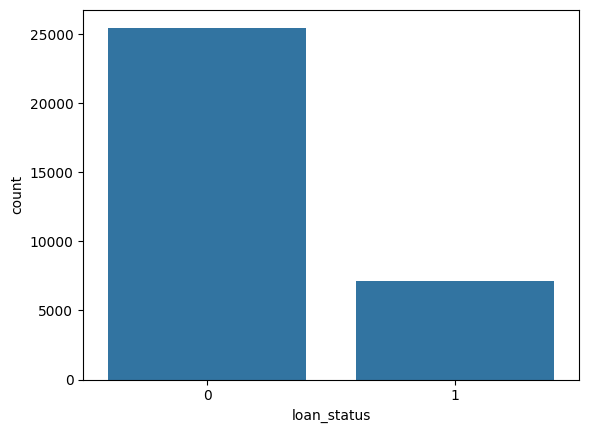

In [11]:
sns.countplot(x="loan_status",data=df)

In [12]:
numerical_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

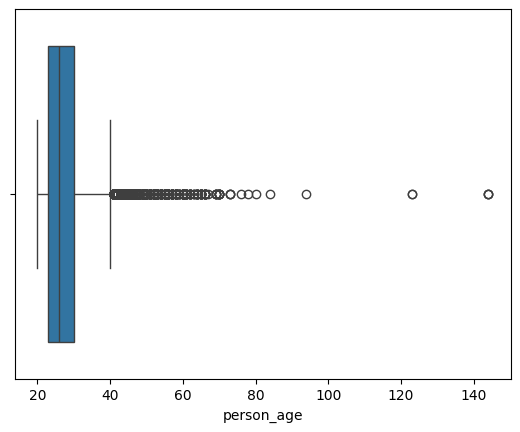

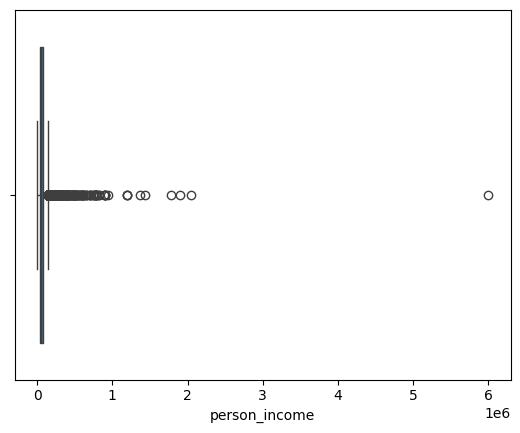

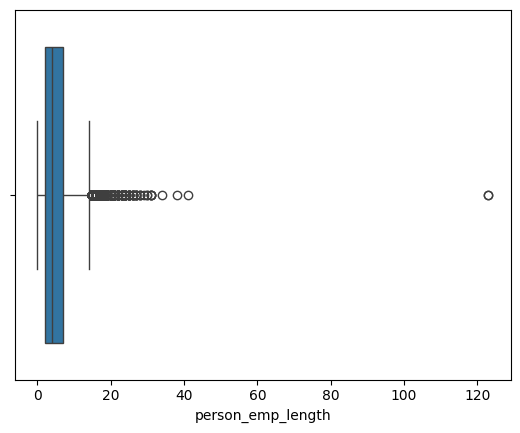

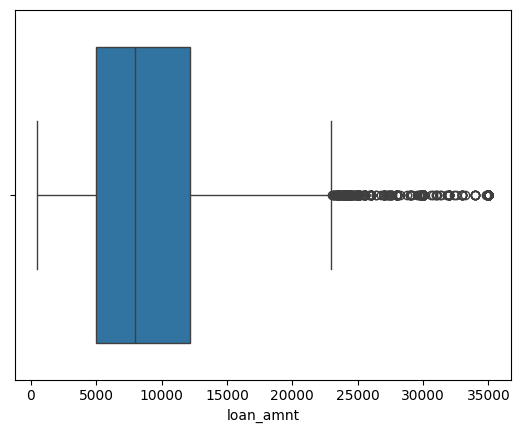

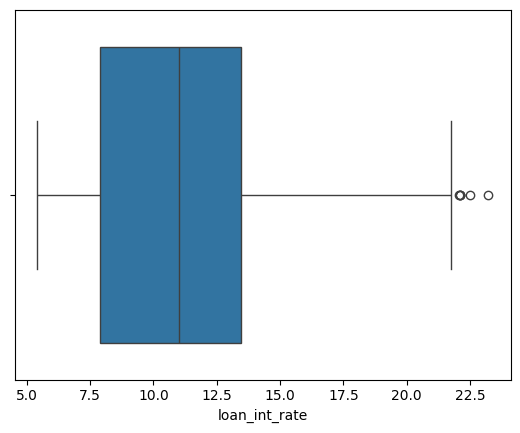

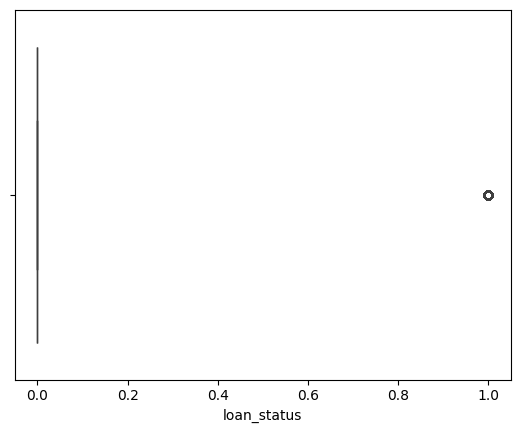

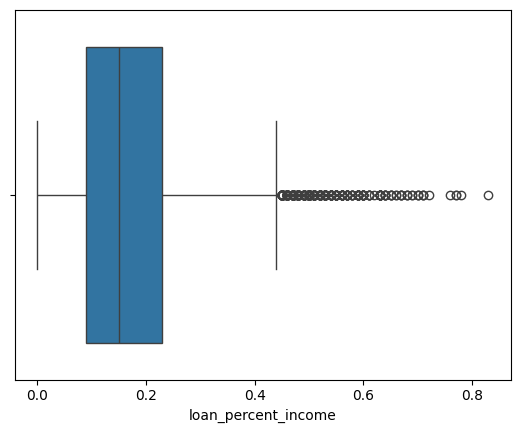

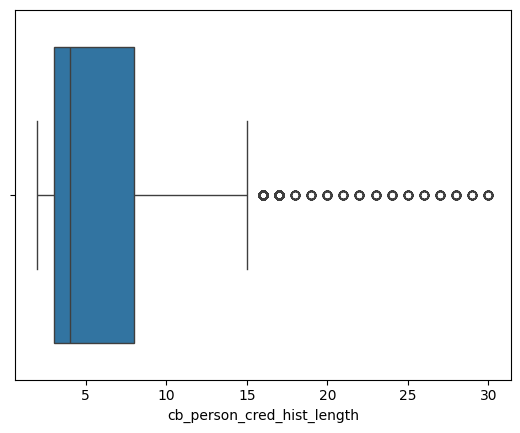

In [13]:
for i in numerical_cols:
  plt.figure()
  sns.boxplot(x=df[i])
  plt.show()

<Axes: >

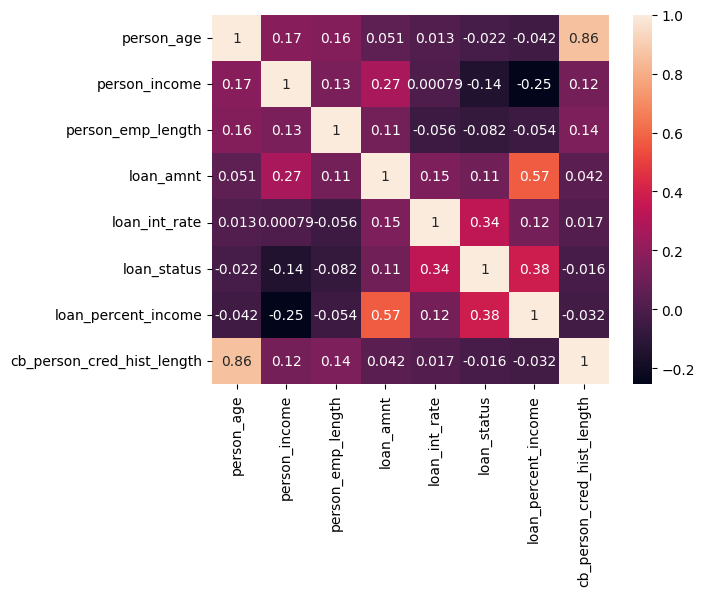

In [14]:
sns.heatmap(df.corr(numeric_only = True),annot=True)

In [15]:
df_copy=df.copy()

In [16]:
print(f"original Rows :{df_copy.shape}")

original Rows :(32581, 12)


In [17]:
df_copy.drop_duplicates(inplace=True)

In [18]:
print(f"Rows after dropping duplicate: {df_copy.shape[0]}")

Rows after dropping duplicate: 32416


In [19]:
# Remov age below than 18 and greater than 60
df_copy= df_copy[df_copy['person_age']>=18]
df_copy=df_copy[df_copy['person_age']<=100]
# Removr employment lenght greater than age or extreme outliers
df_copy=df_copy[df_copy['person_emp_length']<=df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length']<=60]

In [20]:
df_copy = df_copy[df_copy['loan_amnt']>0]

In [21]:
x = df_copy.drop("loan_status",axis=1)
y = df_copy["loan_status"]

In [22]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [23]:
numerical_cols =['person_age' , 'person_income' , 'person_emp_length' ,'loan_amnt' , 'loan_int_rate' , 'loan_percent_income',"cb_person_cred_hist_length"]
categorical_cols = ["person_home_ownership","loan_intent","loan_grade","cb_person_default_on_file"]

In [24]:
# class - weight
y_train.value_counts()

,count
loan_status,
0,19772
1,5445


In [25]:
neg , pos = np.bincount(y_train)

In [26]:
neg

np.int64(19772)

In [27]:
scale_weights = neg/pos
scale_weights

np.float64(3.6312213039485766)

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor_lr = ColumnTransformer(
    transformers =[
        # Pipeline for numerical col
      ("num" , Pipeline([
        ("imputer",SimpleImputer(strategy='median')),
        ("scaler",StandardScaler())
    ]) ,numerical_cols),
        # Pipeline for categorical cols
      ("cat",Pipeline([
        ("imputer",SimpleImputer(strategy='constant' , fill_value="missing")),
        ("onehot",OneHotEncoder(handle_unknown='ignore'))
    ]) ,categorical_cols)
]
)

In [29]:
# XGBoost :- Impute numerical only (No Scaling) , impute + one-Hot

preprocessor_xg = ColumnTransformer(
    transformers =[
        # Pipeline for numerical cols
      ("num" , Pipeline([
        ("imputer",SimpleImputer(strategy='median')),
        ("scaler",StandardScaler())
    ]) ,numerical_cols),
        # Pipeline for categorical cols
      ("cat",Pipeline([
        ("imputer",SimpleImputer(strategy='constant',fill_value="missing")),
        ("onehot",OneHotEncoder(handle_unknown='ignore'))
    ]) ,categorical_cols)
]
)

In [30]:
# Evalute the logistic model and xgboost model on the basis of their metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve
import seaborn as sns
import matplotlib.pyplot as plt

def evalute_model(model_name, model, X_test, y_test , thresholds = None):

  y_pred_prob = model.predict_proba(X_test)[:, 1]
  if thresholds is not None:
    y_pred = (y_pred_prob > thresholds).astype(int)
  else:
    y_pred = model.predict(X_test)
  print(model_name)

  # Using distinct variable names to avoid shadowing imports
  acc = accuracy_score(y_test, y_pred) # Overall models performance
  prec = precision_score(y_test, y_pred) # How model is correctly picking data
  rec = recall_score(y_test, y_pred) # Out of everything that was really there, how much model is able to find
  f1 = f1_score(y_test, y_pred) # Harmonic mean of precision and recall
  roc_auc = roc_auc_score(y_test, y_pred_prob)

  # Confusion matrix
  cm = confusion_matrix(y_test, y_pred)
  class_report = classification_report(y_test, y_pred)
  sns.heatmap(cm, annot=True, fmt='d')
  plt.ylabel('Actual Values')
  plt.xlabel('Predicted Values')
  plt.show()

  # Plotting ROC-AUC Curve
  precision, recall, thresholds = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recall, precision, marker='.')
  plt.xlabel('Recall')
  plt.ylabel('Precision')
  plt.show()

  print(f"Accuracy : {acc}")
  print(f"Precision : {prec}")
  print(f"Recall : {rec}")
  print(f"F1 Score : {f1}")
  print(f"ROC AUC Score : {roc_auc}")

In [31]:
from sklearn.model_selection import StratifiedKFold , cross_validate
cv = StratifiedKFold(n_splits = 5 ,shuffle = True , random_state =42 )
scoring = {'roc_auc':'roc_auc' , 'accuracy':'accuracy' , 'precision':'precision' , 'recall':'recall','f1':'f1'}

In [32]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
   ('preprocessor', preprocessor_lr),
   ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [33]:
#XGboost
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
   ('preprocessor', preprocessor_xg),
   ('classifier', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                                scale_pos_weight=scale_weights, random_state=42))
])

In [34]:
# Re-defining the pipelines to make sure corrected preprocessors are loaded
lr_cv_pipeline = Pipeline([
   ('preprocessor', preprocessor_lr),
   ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

xgb_cv_pipeline = Pipeline([
   ('preprocessor', preprocessor_xg),
   ('classifier', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                                scale_pos_weight=scale_weights, random_state=42))
])

# Running cross-validation with corrected configurations
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                       ("XGBoost", xgb_cv_pipeline)]:
    cv_result = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print(f"=== {cv_name} ===")
    for metric in scoring.keys():
        mean_score = cv_result[f'test_{metric}'].mean()
        print(f"{metric}: {mean_score:.4f}")
    print()

=== Logistic Regression ===
roc_auc: 0.8705
accuracy: 0.8116
precision: 0.5448
recall: 0.7781
f1: 0.6408

=== XGBoost ===
roc_auc: 0.9471
accuracy: 0.9180
precision: 0.8191
recall: 0.7963
f1: 0.8073



In [35]:
cv_result

{'fit_time': array([1.23508286, 1.19286609, 1.20900965, 1.20467997, 0.72128129]),
 'score_time': array([0.18792295, 0.16448402, 0.16465259, 0.16891766, 0.09414053]),
 'test_roc_auc': array([0.95037143, 0.93802547, 0.94787183, 0.94916053, 0.95004373]),
 'test_accuracy': array([0.92089611, 0.91732752, 0.91631965, 0.91929407, 0.91592306]),
 'test_precision': array([0.82485876, 0.836     , 0.81314554, 0.82048872, 0.80090498]),
 'test_recall': array([0.80440771, 0.76767677, 0.79522498, 0.80165289, 0.81267218]),
 'test_f1': array([0.81450488, 0.80038296, 0.80408542, 0.81096145, 0.80674567])}

In [36]:
print(cv_name)
print(f"Roc_AUC : {cv_result['test_roc_auc'].mean()}")
print(f"Accuracy : {cv_result['test_accuracy'].mean()}")

XGBoost
Roc_AUC : 0.9470945968526715
Accuracy : 0.917952083139717


In [37]:
print(cv_name)

XGBoost


1:25:00


Base line model

In [38]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight='balanced'))
])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

In [39]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1, scale_pos_weight=scale_weights))
])
xg_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_valu...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Baseline Logistic Model


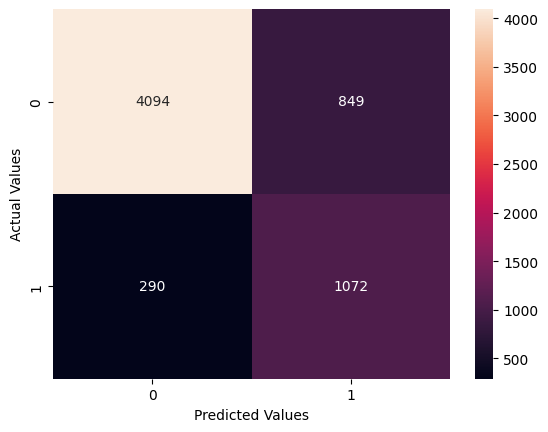

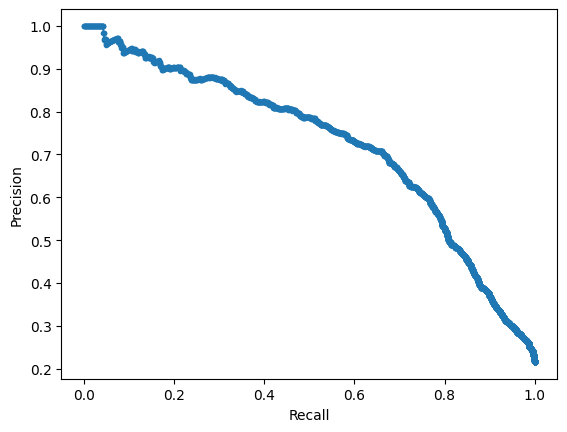

Accuracy : 0.8193497224425059
Precision : 0.5580426861009891
Recall : 0.7870778267254038
F1 Score : 0.6530612244897959
ROC AUC Score : 0.8751287437432844


In [40]:
evalute_model("Baseline Logistic Model" , baseline_model , X_test , y_test)

 Xgboost


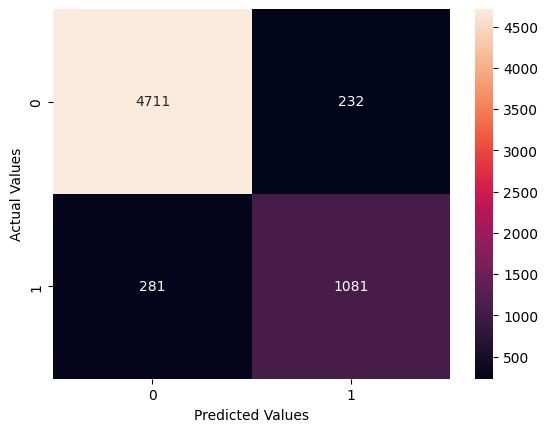

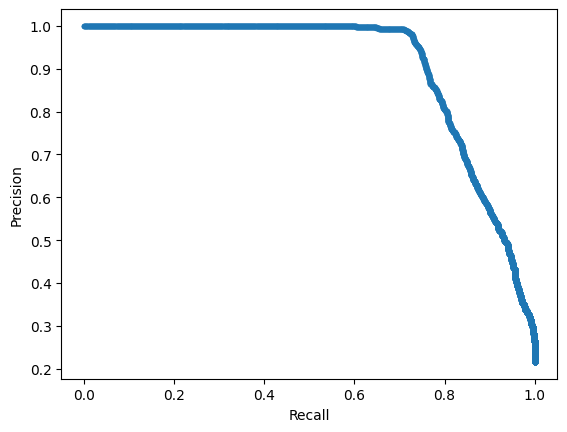

Accuracy : 0.9186360031720856
Precision : 0.8233054074638233
Recall : 0.7936857562408223
F1 Score : 0.8082242990654206
ROC AUC Score : 0.9494647201295949


In [41]:
evalute_model(" Xgboost",xg_model ,X_test ,y_test )

In [42]:
from scipy.stats import uniform, randint

In [43]:
from sklearn.model_selection import RandomizedSearchCV
para_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3, 9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample" : uniform(0.5, 1.0), # Row sampling
    "classifier__colsample_bytree" : uniform(0.5, 1.0), # column sampling
    "classifier__min_child_weight" : randint(1, 10),
    "classifier__gamma" : uniform(0, 5)
}

In [44]:
random_search = RandomizedSearchCV(
    xg_model,
    para_grid,
    n_iter = 150,
    cv=cv,
    scoring ="average_precision",
    n_jobs=1,
    verbose=1
)
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
560 fits failed out of a total of 750.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **l

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income'...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x786708105090>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x78670921fcb0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x786708105450>},
                   scoring='average_precision', verbose=1)

In [45]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8013029359846352),
 'classifier__gamma': np.float64(3.5321870090869796),
 'classifier__learning_rate': np.float64(0.09101793310436594),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': 2,
 'classifier__n_estimators': 247,
 'classifier__subsample': np.float64(0.8349063427618315)}

XGBoost


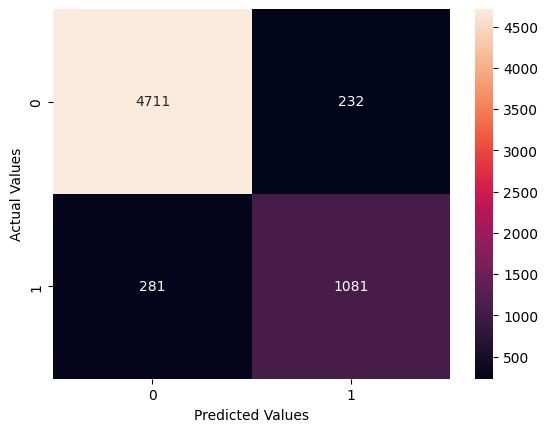

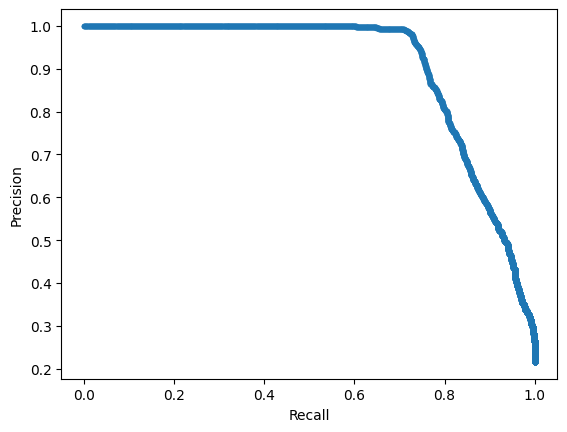

Accuracy : 0.9186360031720856
Precision : 0.8233054074638233
Recall : 0.7936857562408223
F1 Score : 0.8082242990654206
ROC AUC Score : 0.9494647201295949


In [46]:
# passing the model after performing hyper tunning
evalute_model("XGBoost",xg_model,X_test,y_test)

XGboost


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

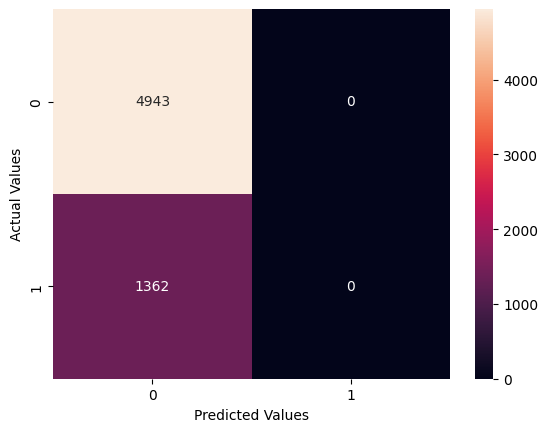

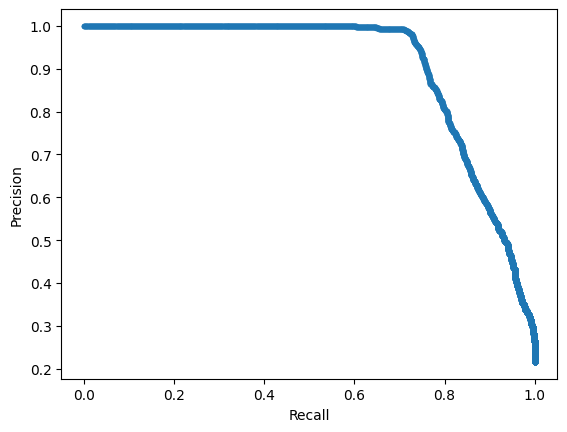

Accuracy : 0.7839809674861221
Precision : 0.0
Recall : 0.0
F1 Score : 0.0
ROC AUC Score : 0.9494647201295949


In [47]:
#Get thr prob. of class 1
prob = xg_model.predict_proba(X_test)[:,1]

# For each thresholds calulate preciosion and Recall
precision , recall , thresholds = precision_recall_curve(y_test ,prob)

# Calculate F1 score for each threshold
f1 = 2 *(precision - recall) / (precision + recall +1e-9 )

# Get the thresholds that produce max f1 score
best = np.argmax(f1[:-1])
best_thresholds = thresholds[best]

# Evalute the xgboost model using that thresholds.
evalute_model("XGboost" , xg_model,X_test ,y_test , best_thresholds)

In [48]:
"""
Method by which we can fix the poorly calibrated model
1. platt scaling / sigmoid function
2. Isotonic Regression --> Learn  a flexible mapping from ild prob. -better
3. Temprature Scaling --> Adjust the confidence of neural network prediction usong one temprature

"""

'\nMethod by which we can fix the poorly calibrated model\n1. platt scaling / sigmoid function\n2. Isotonic Regression --> Learn  a flexible mapping from ild prob. -better\n3. Temprature Scaling --> Adjust the confidence of neural network prediction usong one temprature\n\n'

In [49]:
#1. calibrate the xgboost Model
from sklearn.calibration import CalibratedClassifierCV , calibration_curve
calibrated_model = CalibratedClassifierCV(
    estimator = random_search.best_estimator_,
    method ="sigmoid",
    cv=5
)
calibrated_model.fit(X_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median')),
                                                                                                   ('scaler',
                                                                                                    StandardScaler())]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(ste...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.09101793310436594),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=2,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=247,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [50]:
#2. Get the probabilities
uncalibrated_prob = xg_model.predict_proba(X_test)[:,1]
calibrated_prob = calibrated_model.predict_proba(X_test)[:,1]
uncalibrated_prob

array([0.8254656 , 0.25111562, 0.9782833 , ..., 0.48520026, 0.07587515,
       0.05467961], dtype=float32)

In [51]:
calibrated_prob

array([0.52503715, 0.02569576, 0.95354403, ..., 0.38930621, 0.0202896 ,
       0.01222345])

In [52]:
#3. create a calibrated curve
actual_uncal , predicted_uncal = calibration_curve(y_test , uncalibrated_prob , n_bins=10)
actual_cal , predicted_cal = calibration_curve(y_test , calibrated_prob , n_bins=10)
#

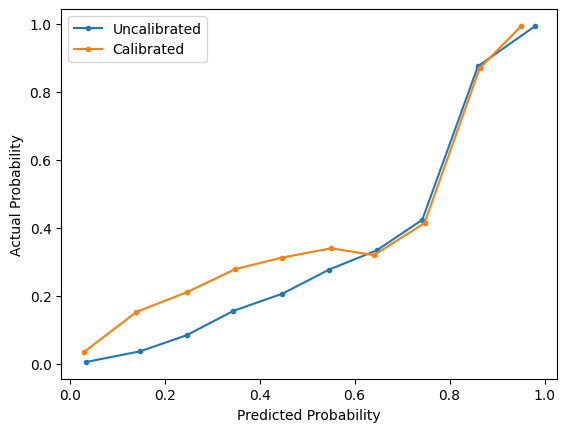

In [53]:
#4 Plot
plt.plot(
    predicted_uncal,
    actual_uncal,
    marker = ".",
    label = "Uncalibrated"
)
plt.plot(
    predicted_cal,
    actual_cal,
    marker = ".",
    label = "Calibrated"
)
plt.legend()
plt.xlabel("Predicted Probability")
plt.ylabel("Actual Probability")
plt.show()

In [55]:
import shap

In [56]:
# Get the Trained XGBoost Classifier model out of the pipeline
xgb_classifier = xg_model.named_steps['classifier']
xgb_classifier

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [57]:
# Transform X_test using the preprocessor used for tranning .
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [58]:
# Get feature names after one-hot encoding , so ploys are readable
feature_name = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [59]:
# convert to a dataframe for cleaner SHAP Plots
X_test_df = pd.DataFrame(X_test_transformed , columns=feature_name)

In [60]:
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,-0.597236,-0.707342,-0.935934,0.850530,1.508838,3.113936,-0.690114,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.759282,-0.125160,0.302506,2.528276,-0.017662,2.455002,-0.442390,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.212991,-0.940215,-0.688246,-0.953839,1.375392,0.289933,0.053058,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.699128,1.233265,0.550194,0.533974,0.535654,-0.651401,0.548506,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.759282,-0.410662,0.550194,1.721058,-0.583997,2.643269,-0.937838,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,-1.083373,0.165931,0.054818,1.641919,0.672355,0.948867,-0.937838,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,0.212991,3.853084,-0.688246,2.433309,0.070218,-0.745534,1.043953,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,-0.435191,-0.338704,0.797882,-0.732250,-0.378944,-0.651401,-0.937838,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,-0.111100,0.942174,1.540945,-0.257416,-1.150331,-0.933801,0.300782,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [61]:
# Create SHAP Explaner buit for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [62]:
explainer

In [63]:
shap_value = explainer.shap_values(X_test_df)
shap_value

array([[-1.7525564e-01, -1.0555401e-01,  1.2984274e-01, ...,
        -7.3516299e-03, -3.8879909e-02,  0.0000000e+00],
       [ 4.7165085e-02, -8.7262326e-01, -9.4737314e-02, ...,
        -9.2151780e-03, -7.5508673e-03,  0.0000000e+00],
       [ 7.8027323e-02,  3.5025654e+00,  1.2711690e-01, ...,
        -7.3584518e-03,  7.7456667e-04,  0.0000000e+00],
       ...,
       [-8.6244913e-03,  5.8208084e-01,  7.2391242e-02, ...,
        -9.2837382e-03, -1.1459960e-02,  0.0000000e+00],
       [ 2.0838849e-02, -1.0313793e+00,  4.3692421e-02, ...,
        -9.2305308e-03, -1.1398584e-02,  0.0000000e+00],
       [-1.3665082e-01, -5.0866711e-01,  2.6854105e-02, ...,
        -8.8342456e-03, -1.0388625e-02,  0.0000000e+00]], dtype=float32)

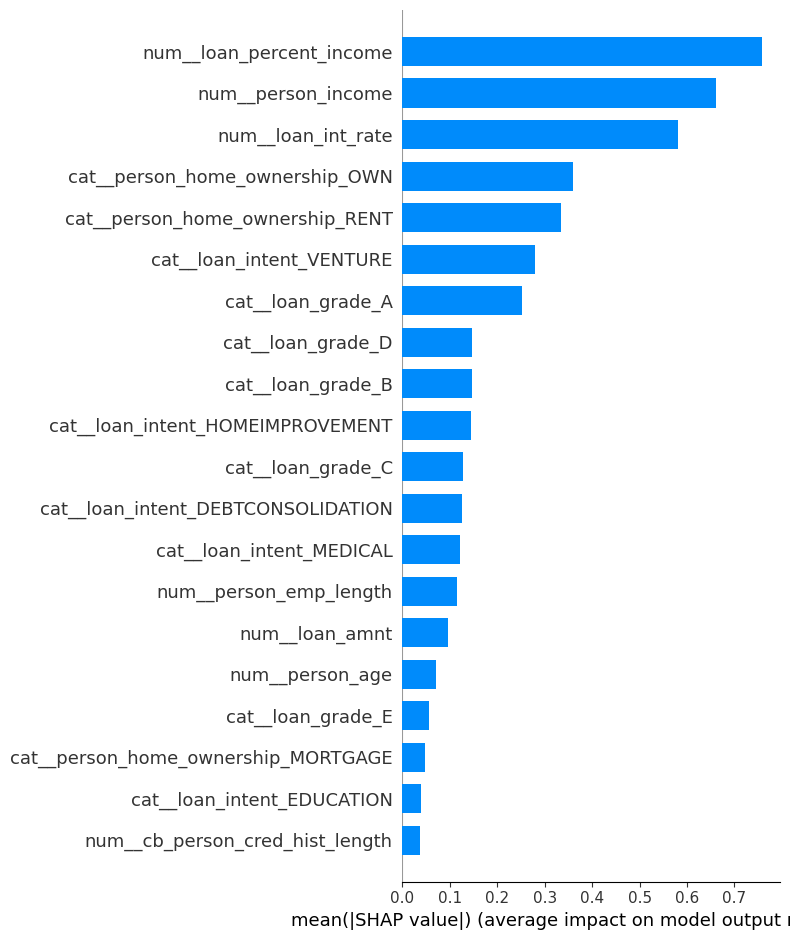

In [64]:
shap.summary_plot(shap_value , X_test_df , plot_type="bar")

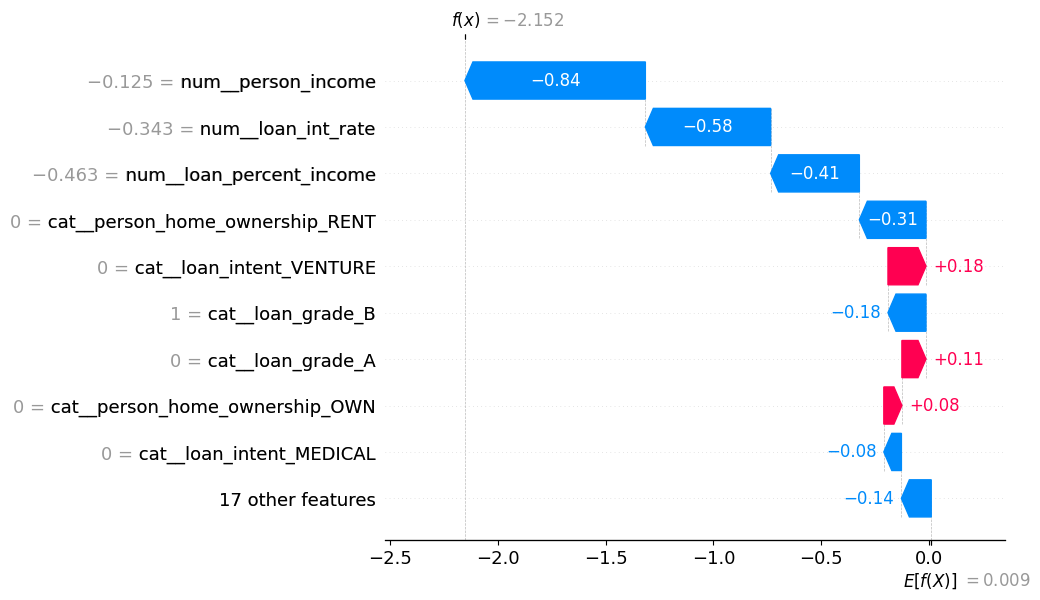

In [65]:
#1. Pick one row to explain  , e.g the 7th applicant in the test set.
row_index = 5

#2. Draw a waterfall plot showing how much each feature pushed  the prdiction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values = shap_value[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = X_test_df.columns
    )
)

In [66]:
# Get Prediction from the best performing XGBoost model on the test set
y_pred = random_search.predict(X_test)

In [67]:
# Create a dataframe to exactly compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [68]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [69]:
# Identify False Positive
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]

#identify False Negative
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]

In [70]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 232
False Negative : 258


In [71]:
import joblib
joblib.dump(calibrated_model , "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [72]:
joblib.dump(best_thresholds , "best_thresholds.pkl")

['best_thresholds.pkl']